# Computer vision

In [2]:
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 19.3 MB/s eta 0:00:00


In [187]:
import random

import torch
from torch import nn
from torch.utils.data import DataLoader

from torchmetrics import Accuracy, ConfusionMatrix

import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from mlxtend.plotting import plot_confusion_matrix

from IPython.display import IFrame

In [4]:
torch.__version__, torchvision.__version__

('2.11.0+cu130', '0.26.0+cu130')

In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"

## Data

In [6]:
train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor(), # how to transform the data
    target_transform=None # how to transform the labels
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.20MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.1MB/s]


In [7]:
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [8]:
len(train_data), len(test_data)

(60000, 10000)

In [9]:
image, label = train_data[0]
image.shape, label # [C,H,W]

(torch.Size([1, 28, 28]), 9)

In [10]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [11]:
train_data.class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

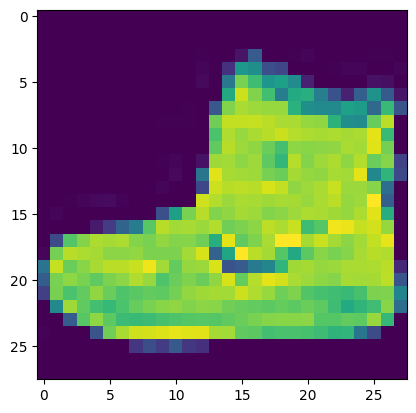

In [12]:
plt.imshow(image.squeeze()) # matplotlib uses [H,W,C]

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

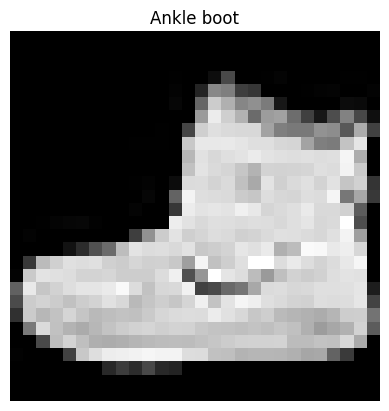

In [13]:
plt.imshow(image.squeeze(),cmap="gray")
plt.title(class_names[label])
plt.axis(False)

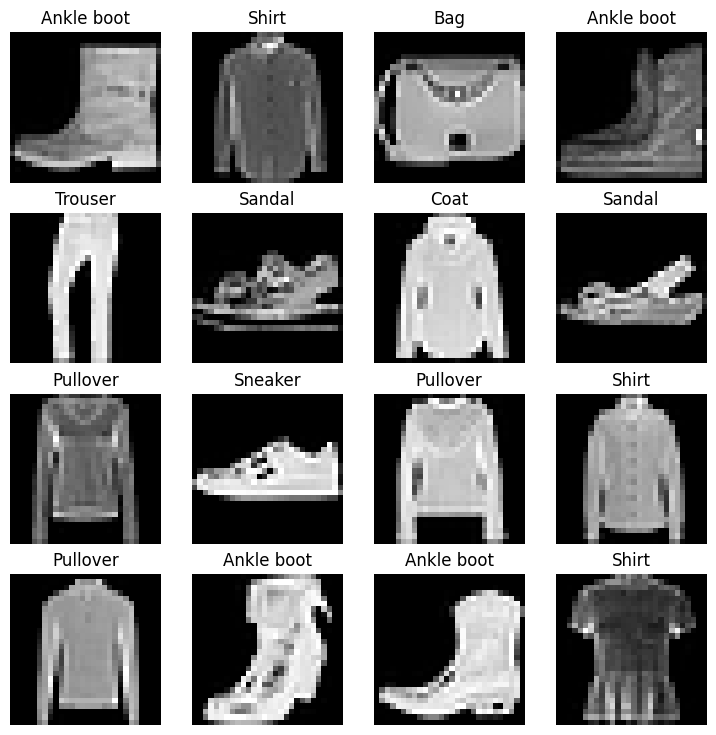

In [14]:
torch.manual_seed(42)
fig = plt.figure(figsize=(9,9))
rows, cols = 4, 4
for i in range(1, rows*cols+1):
  idx = torch.randint(0,len(train_data),size=[1]).item()
  img, lbl = train_data[idx]
  fig.add_subplot(rows,cols,i)
  plt.imshow(img.squeeze(),cmap="gray")
  plt.title(class_names[lbl])
  plt.axis(False)

## DataLoader

- Split the data in batches:
  - More efficient in the use of resources
  - It gives the model more chances to update its gradients per epoch
   

In [15]:
BATCH_SIZE = 32

torch.manual_seed(42)
train_dataloader = DataLoader(train_data,batch_size=BATCH_SIZE,shuffle=True)
test_dataloader = DataLoader(test_data,batch_size=BATCH_SIZE,shuffle=False) # not shuffle so it's easier to debug

In [16]:
len(train_dataloader), len(test_dataloader)

(1875, 313)

In [17]:
train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

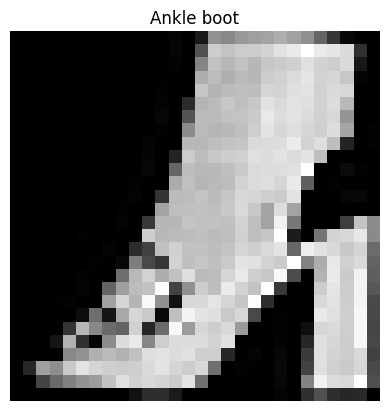

In [18]:
torch.manual_seed(42)
idx = torch.randint(0,len(train_features_batch),size=[1]).item()
img, lbl = train_features_batch[idx], train_labels_batch[idx]
plt.imshow(img.squeeze(),cmap="gray")
plt.title(class_names[lbl])
plt.axis(False)

## Utils

In [19]:
def train_model(epochs,model,train_dataloader,test_dataloader,loss_fn,optimizer,accuracy_fn,device):
  torch.manual_seed(42)

  for epoch in tqdm(range(epochs)):
    train_loss, train_acc = 0, 0

    for batch, (X, y) in enumerate(train_dataloader):
      X, y = X.to(device), y.to(device)
      model.train()
      y_pred = model(X)
      loss = loss_fn(y_pred, y)
      train_loss += loss
      train_acc += accuracy_fn(y_pred.argmax(dim=1),y)
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      if batch % 500 == 0:
        print(f"Batch: {batch} Samples: {batch*len(X)}/{len(train_dataloader.dataset)}")

    print(f"Batch: {batch} Samples: {batch*len(X)}/{len(train_dataloader.dataset)}")

    train_loss /= len(train_dataloader)
    train_acc /= len(train_dataloader)

    test_loss, test_acc = 0, 0
    model.eval()
    with torch.inference_mode():
      for X_test, y_test in test_dataloader:
        X_test, y_test = X_test.to(device), y_test.to(device)
        test_pred = model(X_test)
        test_loss += loss_fn(test_pred,y_test)
        test_acc += accuracy_fn(test_pred.argmax(dim=1),y_test)

      test_loss /= len(test_dataloader)
      test_acc /= len(test_dataloader)

    print(f"Epoch: {epoch} Train loss: {train_loss:.4f} Train acc: {train_acc:.4f} Test loss: {test_loss:.4f} Test acc: {test_acc:.4f}\n")

In [20]:
def eval_model(model,data_loader,loss_fn,accuracy_fn):
  torch.manual_seed(42)
  loss, acc = 0, 0
  model.eval()
  with torch.inference_mode():
    for X, y in data_loader:
      X, y = X.to(device), y.to(device)
      y_pred = model(X)
      loss += loss_fn(y_pred,y)
      acc += accuracy_fn(y_pred.argmax(dim=1),y)
    loss /= len(data_loader)
    acc /= len(data_loader)
  return {"model_name": model.__class__.__name__, "model_loss": loss.item(), "model_acc": acc.item()}

## Model 0

In [21]:
flatten_model = nn.Flatten()
output = flatten_model(torch.rand([32,1,28,28]))
output.shape, 28*28

(torch.Size([32, 784]), 784)

In [22]:
class Model(nn.Module):
  def __init__(self,in_features,hidden_units,out_features):
    super().__init__()
    self.layers = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=in_features,out_features=hidden_units),
        nn.Linear(in_features=hidden_units,out_features=out_features)
    )

  def forward(self,x):
    return self.layers(x)

In [23]:
torch.manual_seed(42)

model = Model(28*28,10,len(class_names)).to(device)
model

Model(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [24]:
model(torch.rand([32,1,28,28]).to(device)).shape

torch.Size([32, 10])

In [25]:
loss_fn = nn.CrossEntropyLoss() # multi-class data
optimizer = torch.optim.SGD(params=model.parameters(),lr=0.03)

In [26]:
accuracy_fn = Accuracy(task="multiclass", num_classes=len(class_names)).to(device)

In [27]:
%%time
train_model(3,model,train_dataloader,test_dataloader,loss_fn,optimizer,accuracy_fn,device)

  0%|          | 0/3 [00:00<?, ?it/s]

Batch: 0 Samples: 0/60000
Batch: 500 Samples: 16000/60000
Batch: 1000 Samples: 32000/60000
Batch: 1500 Samples: 48000/60000
Batch: 1874 Samples: 59968/60000
Epoch: 0 Train loss: 0.6746 Train acc: 0.7725 Test loss: 0.5209 Test acc: 0.8171

Batch: 0 Samples: 0/60000
Batch: 500 Samples: 16000/60000
Batch: 1000 Samples: 32000/60000
Batch: 1500 Samples: 48000/60000
Batch: 1874 Samples: 59968/60000
Epoch: 1 Train loss: 0.4842 Train acc: 0.8305 Test loss: 0.4821 Test acc: 0.8308

Batch: 0 Samples: 0/60000
Batch: 500 Samples: 16000/60000
Batch: 1000 Samples: 32000/60000
Batch: 1500 Samples: 48000/60000
Batch: 1874 Samples: 59968/60000
Epoch: 2 Train loss: 0.4559 Train acc: 0.8410 Test loss: 0.4706 Test acc: 0.8349

CPU times: user 37.8 s, sys: 339 ms, total: 38.1 s
Wall time: 38.6 s


In [28]:
for batch, (X, y) in enumerate(train_dataloader):
  print(batch,X.shape,y.shape)
  break

0 torch.Size([32, 1, 28, 28]) torch.Size([32])


In [29]:
eval_model(model,test_dataloader,loss_fn,accuracy_fn)

{'model_name': 'Model',
 'model_loss': 0.4705964922904968,
 'model_acc': 0.8348641991615295}

## Model 1

In [30]:
class Model(nn.Module):
  def __init__(self,in_features,hidden_units,out_features):
    super().__init__()
    self.layers = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=in_features,out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units,out_features=out_features),
        nn.ReLU(),
    )

  def forward(self,x):
    return self.layers(x)

In [31]:
torch.manual_seed(42)

model = Model(28*28,10,len(class_names)).to(device)
model

Model(
  (layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): ReLU()
    (3): Linear(in_features=10, out_features=10, bias=True)
    (4): ReLU()
  )
)

In [104]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model.parameters(),lr=0.1)

In [33]:
%%time
train_model(3,model,train_dataloader,test_dataloader,loss_fn,optimizer,accuracy_fn,device)

  0%|          | 0/3 [00:00<?, ?it/s]

Batch: 0 Samples: 0/60000
Batch: 500 Samples: 16000/60000
Batch: 1000 Samples: 32000/60000
Batch: 1500 Samples: 48000/60000
Batch: 1874 Samples: 59968/60000
Epoch: 0 Train loss: 1.0920 Train acc: 0.6134 Test loss: 0.9564 Test acc: 0.6500

Batch: 0 Samples: 0/60000
Batch: 500 Samples: 16000/60000
Batch: 1000 Samples: 32000/60000
Batch: 1500 Samples: 48000/60000
Batch: 1874 Samples: 59968/60000
Epoch: 1 Train loss: 0.7810 Train acc: 0.7193 Test loss: 0.7223 Test acc: 0.7391

Batch: 0 Samples: 0/60000
Batch: 500 Samples: 16000/60000
Batch: 1000 Samples: 32000/60000
Batch: 1500 Samples: 48000/60000
Batch: 1874 Samples: 59968/60000
Epoch: 2 Train loss: 0.6703 Train acc: 0.7594 Test loss: 0.6850 Test acc: 0.7502

CPU times: user 38.6 s, sys: 271 ms, total: 38.9 s
Wall time: 40.3 s


In [34]:
eval_model(model,test_dataloader,loss_fn,accuracy_fn)

{'model_name': 'Model',
 'model_loss': 0.6850008964538574,
 'model_acc': 0.7501996755599976}

## Model 2

In [1]:
IFrame("https://poloclub.github.io/cnn-explainer", width=800, height=600)

In [108]:
class Model(nn.Module):
  """
  TinyVGG
  """
  def __init__(self,in_features,hidden_units,out_features):
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(
          in_channels=in_features,
          out_channels=hidden_units,
          kernel_size=3,
          stride=1,
          padding=1,
        ),
        nn.ReLU(),
        nn.Conv2d(
          in_channels=hidden_units,
          out_channels=hidden_units,
          kernel_size=3,
          stride=1,
          padding=1,
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
    )
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(
          in_channels=hidden_units,
          out_channels=hidden_units,
          kernel_size=3,
          stride=1,
          padding=1,
        ),
        nn.ReLU(),
        nn.Conv2d(
          in_channels=hidden_units,
          out_channels=hidden_units,
          kernel_size=3,
          stride=1,
          padding=1,
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
    )
    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*7*7,out_features=out_features),
    )

  def forward(self,x):
    # print(x.shape)
    x = self.conv_block_1(x)
    # print(x.shape)
    x = self.conv_block_2(x)
    # print(x.shape)
    x = self.classifier(x)
    # print(x.shape)
    return x

In [98]:
flatten_model = nn.Flatten()
output = flatten_model(torch.rand([1,10,7,7]))
output.shape, 10*7*7

(torch.Size([1, 490]), 490)

In [109]:
torch.manual_seed(42)

model = Model(1,10,len(class_names)).to(device) # 1 channel
model

Model(
  (conv_block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)

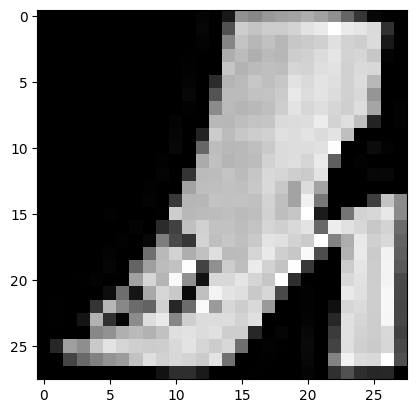

In [100]:
plt.imshow(img.squeeze(),cmap="gray")

In [103]:
torch.manual_seed(42)
_ = model(img.unsqueeze(0).to(device))

torch.Size([1, 1, 28, 28])
torch.Size([1, 10, 14, 14])
torch.Size([1, 10, 7, 7])
torch.Size([1, 10])


In [66]:
torch.manual_seed(42)

images = torch.randn((32,1,64,64)).to(device)
test_image = images[0]

images.shape, test_image.shape

(torch.Size([32, 1, 64, 64]), torch.Size([1, 64, 64]))

In [67]:
conv_layer = nn.Conv2d(
  in_channels=test_image.shape[0],
  out_channels=10,
  kernel_size=(3,3),
  stride=2, # the kernel moves one pixel at a time as it slides
  padding=1, # adds pixels before conv. different reasons (keep size, use border pixels fairly, etc)
).to(device)
conv_out = conv_layer(test_image)

conv_out.shape

torch.Size([10, 32, 32])

In [68]:
max_pool_layer = nn.MaxPool2d(kernel_size=2).to(device)
max_pool_out = max_pool_layer(conv_out)

max_pool_out.shape

torch.Size([10, 16, 16])

In [111]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model.parameters(),lr=0.1)

In [112]:
%%time
train_model(3,model,train_dataloader,test_dataloader,loss_fn,optimizer,accuracy_fn,device)

  0%|          | 0/3 [00:00<?, ?it/s]

Batch: 0 Samples: 0/60000
Batch: 500 Samples: 16000/60000
Batch: 1000 Samples: 32000/60000
Batch: 1500 Samples: 48000/60000
Batch: 1874 Samples: 59968/60000
Epoch: 0 Train loss: 0.5908 Train acc: 0.7851 Test loss: 0.3930 Test acc: 0.8587

Batch: 0 Samples: 0/60000
Batch: 500 Samples: 16000/60000
Batch: 1000 Samples: 32000/60000
Batch: 1500 Samples: 48000/60000
Batch: 1874 Samples: 59968/60000
Epoch: 1 Train loss: 0.3590 Train acc: 0.8702 Test loss: 0.3505 Test acc: 0.8673

Batch: 0 Samples: 0/60000
Batch: 500 Samples: 16000/60000
Batch: 1000 Samples: 32000/60000
Batch: 1500 Samples: 48000/60000
Batch: 1874 Samples: 59968/60000
Epoch: 2 Train loss: 0.3218 Train acc: 0.8841 Test loss: 0.3409 Test acc: 0.8767

CPU times: user 43.1 s, sys: 220 ms, total: 43.3 s
Wall time: 44 s


In [114]:
eval_model(model,test_dataloader,loss_fn,accuracy_fn)

{'model_name': 'Model',
 'model_loss': 0.3409339487552643,
 'model_acc': 0.8766972422599792}

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

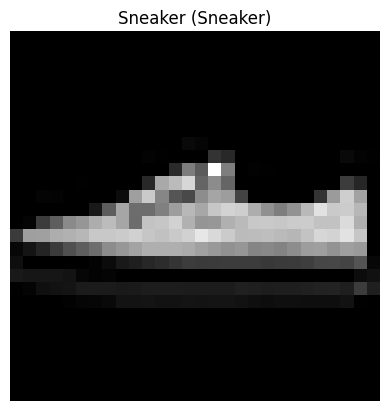

In [143]:
idx = torch.randint(0,len(train_features_batch),size=[1]).item()
img, lbl = train_features_batch[idx], train_labels_batch[idx]

model.eval()
with torch.inference_mode():
  sample = img.unsqueeze(0).to(device)
  logit = model(sample)
  prob = torch.argmax(logit.squeeze(),dim=0).to("cpu")

plt.imshow(img.squeeze(),cmap="gray")
plt.title(f"{class_names[lbl]} ({class_names[prob]})")
plt.axis(False)

In [159]:
def predict(model,data,device):
  probs = []
  model.to(device)
  model.eval()
  with torch.inference_mode():
    for sample in data:
      sample = torch.unsqueeze(sample,0).to(device)
      logit = model(sample)
      prob = torch.argmax(logit.squeeze(),dim=0)
      probs.append(prob)
  return torch.stack(probs).cpu()

In [169]:
random.seed(42)

test_samples = []
test_labels = []
for sample, label in random.sample(list(test_data), k=16):
  test_samples.append(sample)
  test_labels.append(label)

probs = predict(model,test_samples,device)
test_samples = torch.stack(test_samples).cpu()

probs.shape, test_samples.shape

(torch.Size([16]), torch.Size([16, 1, 28, 28]))

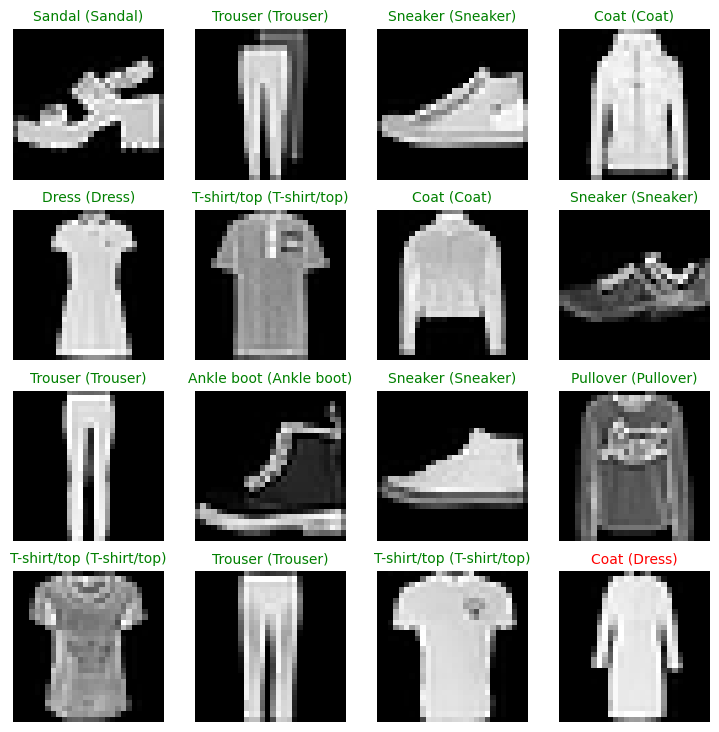

In [172]:
fig = plt.figure(figsize=(9,9))
rows, cols = 4, 4
for i in range(len(test_samples)):
  img, lbl = test_samples[i], test_labels[i]
  prob = probs[i]
  fig.add_subplot(rows,cols,i+1)
  plt.imshow(img.squeeze(),cmap="gray")
  if class_names[lbl] == class_names[prob]:
    plt.title(f"{class_names[lbl]} ({class_names[prob]})", fontsize=10, c="g")
  else:
    plt.title(f"{class_names[lbl]} ({class_names[prob]})", fontsize=10, c="r")
  plt.axis(False)

In [176]:
y_preds = []
model.eval()
with torch.inference_mode():
  for X, y in tqdm(test_dataloader):
    X, y = X.to(device), y.to(device)
    y_logit = model(X)
    y_pred = torch.softmax(y_logit.squeeze(),dim=0).argmax(dim=1)
    y_preds.append(y_pred)
y_preds = torch.cat(y_preds).cpu()

y_preds.shape

  0%|          | 0/313 [00:00<?, ?it/s]

torch.Size([10000])

In [182]:
conf = ConfusionMatrix(num_classes=len(class_names),task="multiclass")
conf_tensor = conf(preds=y_preds,target=test_data.targets)
conf_tensor

tensor([[665,   5,  56,  75,  10,   0, 181,   0,   8,   0],
        [  9, 846,  11, 111,  15,   3,   3,   0,   1,   1],
        [  8,   2, 789,  11, 112,   0,  73,   0,   5,   0],
        [ 23,  11,  39, 846,  46,   0,  31,   0,   3,   1],
        [  3,   2, 108,  40, 721,   0, 123,   0,   3,   0],
        [ 10,   0,   4,  20,   1, 812,   1,  56,  76,  20],
        [ 81,   5, 126,  67,  82,   1, 628,   0,  10,   0],
        [  1,   1,   0,   0,   0,  27,   0, 899,  13,  59],
        [ 15,   1,  18,  16,  14,   8,  49,   7, 870,   2],
        [  0,   1,   1,   4,   0,  21,   5,  84,  11, 873]])

(<Figure size 1000x700 with 1 Axes>,
 <Axes: xlabel='predicted label', ylabel='true label'>)

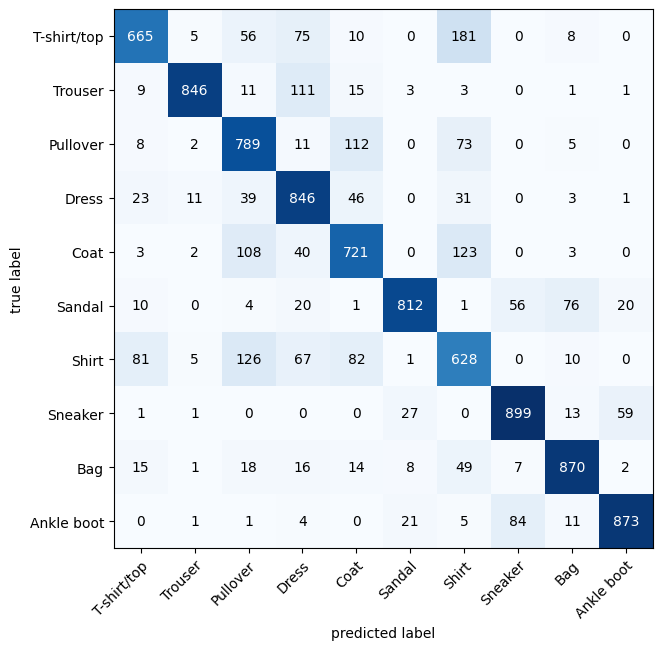

In [186]:
plot_confusion_matrix(conf_tensor.numpy(),class_names=class_names,figsize=(10,7))

In [197]:
a = eval_model(model,test_dataloader,loss_fn,accuracy_fn)
torch.save(model.state_dict(),"model")
model = Model(1,10,len(class_names))
model.load_state_dict(torch.load("model"))
model.to(device)
b = eval_model(model,test_dataloader,loss_fn,accuracy_fn)
torch.isclose(torch.tensor(a["model_loss"]),torch.tensor(b["model_loss"]))

tensor(True)